<a href="https://colab.research.google.com/github/satyapal2240/satya/blob/main/SNG_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# CELL 1: Install dependencies (Google Colab)
!pip -q install numpy pandas matplotlib scikit-learn torch scipy
print("Required packages are ready.")

Required packages are ready.


In [ ]:
# CELL 2: Import libraries and set reproducible seeds
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device("cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)


PyTorch: 2.14.1+cpu
Device: cpu


In [ ]:
# CELL 3: Generate the synthetic dataset and calculate peak temperature

R_GAS = 8.314462618       # J mol-1 K-1
P_STD = 101325.0          # Pa
T_STD = 273.15            # K
V_BED = 0.010             # m3; assumed 10 L catalyst-bed volume
RECYCLE_RATIO_BASE = 10.0 # recycle/fresh-feed; assumed scenario
DELTA_H = 206300.0        # J/mol CO; magnitude of exothermic reaction enthalpy
T_SCREEN = 823.0          # K; screening threshold used in this study

# NIST Shomate coefficients; Cp in J mol-1 K-1, t = T/1000.
SHOMATE_CO = {"A": 25.56759, "B": 6.096130, "C": 4.054656,
              "D": -2.671301, "E": 0.131021}
SHOMATE_H2 = {"A": 33.066178, "B": -11.363417, "C": 11.432816,
              "D": -2.772874, "E": -0.158558}

def cp_shomate(T_K, coeff):
    t = T_K / 1000.0
    return (coeff["A"] + coeff["B"]*t + coeff["C"]*t**2
            + coeff["D"]*t**3 + coeff["E"]/(t**2))

def calculate_peak_temperature(T_inlet_K, pressure_bar, ghsv_h1,
                               h2_co_ratio, eta_co, recycle_ratio):
    # Fresh-feed standard volumetric and molar flow rates
    vdot_std = ghsv_h1 * V_BED / 3600.0       # m3/s at standard conditions
    n_fresh = P_STD * vdot_std / (R_GAS*T_STD) # mol/s
    f_co = n_fresh / (1.0 + h2_co_ratio)       # mol CO/s in fresh feed

    # Recycled gas is assumed to have the same composition as fresh syngas.
    n_total = n_fresh * (1.0 + recycle_ratio)
    x_co = 1.0 / (1.0 + h2_co_ratio)
    x_h2 = h2_co_ratio / (1.0 + h2_co_ratio)

    mw_mix = x_co*0.02801 + x_h2*0.002016       # kg/mol
    cp_molar = x_co*cp_shomate(T_inlet_K, SHOMATE_CO) + \
               x_h2*cp_shomate(T_inlet_K, SHOMATE_H2)
    cp_mass = cp_molar / mw_mix                 # J kg-1 K-1

    p_abs = pressure_bar * 1e5                  # Pa
    vdot_spatial = n_total * R_GAS*T_inlet_K/p_abs
    rho_mix = p_abs*mw_mix/(R_GAS*T_inlet_K)   # kg/m3

    q_release = DELTA_H * f_co * eta_co         # W
    delta_T = q_release / (rho_mix*cp_mass*vdot_spatial)
    return T_inlet_K + delta_T

np.random.seed(42)
num_samples = 1000

T_inlet = np.random.uniform(523, 723, num_samples)
Pressure = np.random.uniform(10, 35, num_samples)       # bar absolute
GHSV = np.random.uniform(5000, 15000, num_samples)      # h-1, STP basis
H2_CO_ratio = np.random.uniform(2.5, 3.5, num_samples)

# This is a constructed synthetic response function, not an LHHW rate model.
base_conversion = 0.98 - 0.001*(T_inlet - 523) + 0.002*(Pressure - 10)
yield_fraction_raw = np.clip(
    base_conversion*(1.0 - 0.05*np.abs(H2_CO_ratio - 3.0)), 0.60, 0.995
)

# Hydrogen stoichiometry limits the maximum CO conversion to H2/CO divided by 3.
yield_fraction = np.minimum(yield_fraction_raw, H2_CO_ratio/3.0)
CH4_Yield = yield_fraction * 100.0

T_peak = np.array([
    calculate_peak_temperature(T_inlet[i], Pressure[i], GHSV[i],
                               H2_CO_ratio[i], yield_fraction[i],
                               RECYCLE_RATIO_BASE)
    for i in range(num_samples)
])

Catalyst_State = np.where(T_peak > T_SCREEN,
                          "Above_Screening_Limit",
                          "Below_Screening_Limit")

df = pd.DataFrame({
    "Sample_ID": np.arange(1, num_samples+1),
    "Inlet_Temperature_K": np.round(T_inlet, 2),
    "Operating_Pressure_bar": np.round(Pressure, 2),
    "Flow_Rate_GHSV_h1": np.round(GHSV, 0),
    "H2_CO_Stoich_Ratio": np.round(H2_CO_ratio, 3),
    "Peak_Hotspot_Temp_K": np.round(T_peak, 2),
    "SNG_CH4_Yield_Percent": np.round(CH4_Yield, 2),
    "Catalyst_Health_Status": Catalyst_State
})

print("Dataset shape:", df.shape)
print("Only four operating variables are used as model inputs.")
print("Peak-temperature range:", round(T_peak.min(), 2), "to", round(T_peak.max(), 2), "K")
print("Mean peak temperature:", round(T_peak.mean(), 2), "K")
print("Samples above 823 K:", int(np.sum(T_peak > T_SCREEN)), "of", num_samples)
display(df.head())
display(df["Catalyst_Health_Status"].value_counts().to_frame("Sample_Count"))

df.to_csv("sng_thermodynamic_dataset_revised.csv", index=False)
print("Saved: sng_thermodynamic_dataset_revised.csv")

Dataset shape: (1000, 8)
Only four operating variables are used as model inputs.
Peak-temperature range: 663.92 to 859.59 K
Mean peak temperature: 761.88 K
Samples above 823 K: 156 of 1000


,Sample_ID,Inlet_Temperature_K,Operating_Pressure_bar,Flow_Rate_GHSV_h1,H2_CO_Stoich_Ratio,Peak_Hotspot_Temp_K,SNG_CH4_Yield_Percent,Catalyst_Health_Status
0,1,597.91,14.63,7617.0,3.173,735.57,90.65,Below_Screening_Limit
1,2,713.14,23.55,7470.0,3.297,830.71,80.48,Above_Screening_Limit
2,3,669.40,31.82,14063.0,2.750,814.71,86.63,Below_Screening_Limit
3,4,642.73,28.31,7495.0,3.125,779.15,89.13,Below_Screening_Limit
4,5,554.20,30.16,7719.0,3.072,708.06,98.56,Below_Screening_Limit


,Sample_Count
Catalyst_Health_Status,
Below_Screening_Limit,844
Above_Screening_Limit,156


Saved: sng_thermodynamic_dataset_revised.csv


In [ ]:
# CELL 4: Split first, then fit scalers on training data only
torch.manual_seed(42)
feature_cols = [
    "Inlet_Temperature_K",
    "Operating_Pressure_bar",
    "Flow_Rate_GHSV_h1",
    "H2_CO_Stoich_Ratio"
]
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df["SNG_CH4_Yield_Percent"].to_numpy(dtype=np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler_X.transform(X_test).astype(np.float32)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).astype(np.float32)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32, device=DEVICE)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32, device=DEVICE)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE)

class PhysicsConstrainedPINN(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.network(x)

    def physics_loss(self, x_scaled, y_pred_scaled):
        y_pred = y_pred_scaled*float(scaler_y.scale_[0]) + float(scaler_y.mean_[0])
        ratio = x_scaled[:, 3]*float(scaler_X.scale_[3]) + float(scaler_X.mean_[3])
        upper_bound = ratio/3.0*100.0
        violation = torch.relu(-y_pred) + torch.relu(y_pred-upper_bound)
        return torch.mean(violation**2)/10000.0

pinn = PhysicsConstrainedPINN().to(DEVICE)
optimizer = optim.Adam(pinn.parameters(), lr=0.001)
criterion = nn.MSELoss()
lambda_phys = 10.0
epochs = 800

loss_history = []
pinn.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    y_pred_train = pinn(X_train_t)
    loss_data = criterion(y_pred_train, y_train_t)
    loss_phys = pinn.physics_loss(X_train_t, y_pred_train)
    loss = loss_data + lambda_phys*loss_phys
    loss.backward()
    optimizer.step()
    loss_history.append(float(loss.item()))

print(f"PINN training completed for {epochs} epochs.")
print("Final combined loss:", round(loss_history[-1], 6))

# Classical baselines use the same training and test partitions.
ann = MLPRegressor(
    hidden_layer_sizes=(64, 64), activation="tanh",
    max_iter=1000, random_state=42, early_stopping=True
)
rf = RandomForestRegressor(
    n_estimators=200, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
ann.fit(X_train_scaled, y_train)
rf.fit(X_train_scaled, y_train)
print("ANN and Random Forest training completed.")


PINN training completed for 800 epochs.
Final combined loss: 0.007743
ANN and Random Forest training completed.


Test-set performance (yield errors are percentage points):


,RMSE,MAE,R2,Physical_Violations_pct
Standard ANN,1.5260,0.8844,0.9240,12.5
Random Forest,0.5387,0.4035,0.9905,12.5
Proposed PINN,0.1853,0.1251,0.9989,0.0


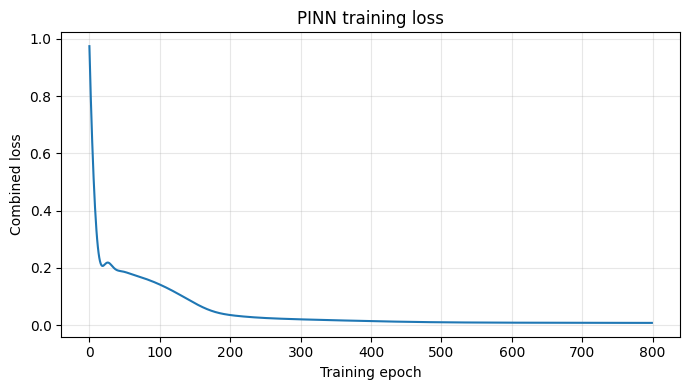

PINN CPU inference time for a batch of 100: 0.536 ms


In [ ]:
# CELL 5: Evaluate models and apply the PINN feasibility projection
pinn.eval()
with torch.no_grad():
    pinn_pred_scaled = pinn(X_test_t).cpu().numpy().reshape(-1)
pinn_pred_raw = pinn_pred_scaled*scaler_y.scale_[0] + scaler_y.mean_[0]

# Final physical projection: 0 <= yield <= min(100, 100*H2/CO/3).
test_upper_bound = np.minimum(100.0, X_test[:, 3]/3.0*100.0)
pinn_pred = np.clip(pinn_pred_raw, 0.0, test_upper_bound)

ann_pred = ann.predict(X_test_scaled)
rf_pred = rf.predict(X_test_scaled)

def model_metrics(y_true, y_pred, upper):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
        "Physical_Violations_pct": float(
            np.mean((y_pred < 0.0) | (y_pred > upper + 1e-9))*100.0
        )
    }

metrics = {
    "Standard ANN": model_metrics(y_test, ann_pred, test_upper_bound),
    "Random Forest": model_metrics(y_test, rf_pred, test_upper_bound),
    "Proposed PINN": model_metrics(y_test, pinn_pred, test_upper_bound)
}
results = pd.DataFrame(metrics).T
print("Test-set performance (yield errors are percentage points):")
display(results.round(4))

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Training epoch")
plt.ylabel("Combined loss")
plt.title("PINN training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pinn_training_loss_revised.png", dpi=250)
plt.show()

# CPU inference timing; actual values depend on the computer used.
sample_batch = X_test_t[:100]
with torch.no_grad():
    start = time.perf_counter()
    for _ in range(200):
        _ = pinn(sample_batch)
    pinn_ms = (time.perf_counter()-start)/200*1000
print(f"PINN CPU inference time for a batch of 100: {pinn_ms:.3f} ms")


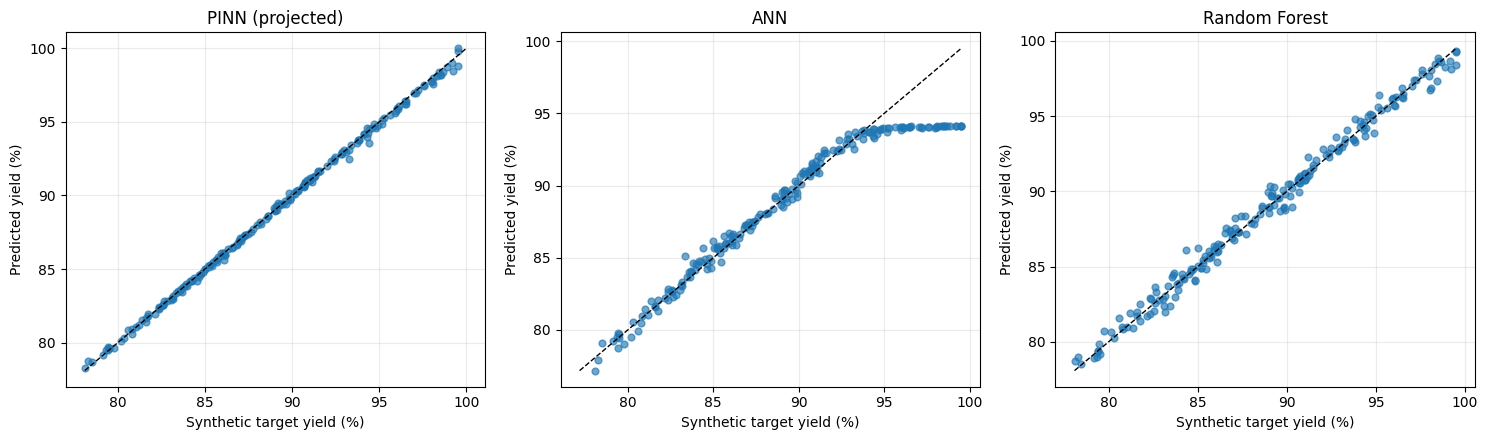

In [ ]:
# CELL 6: Prediction plots
predictions = {
    "PINN (projected)": pinn_pred,
    "ANN": ann_pred,
    "Random Forest": rf_pred
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.65, s=24)
    low = min(float(y_test.min()), float(pred.min()))
    high = max(float(y_test.max()), float(pred.max()))
    ax.plot([low, high], [low, high], "k--", linewidth=1)
    ax.set_xlabel("Synthetic target yield (%)")
    ax.set_ylabel("Predicted yield (%)")
    ax.set_title(name)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("yield_prediction_comparison_revised.png", dpi=250)
plt.show()


,Recycle_Ratio,Minimum_Tpeak_K,Maximum_Tpeak_K,Mean_Tpeak_K,Samples_Above_823K_pct
0,0:1,1931.72,2330.36,2170.19,100.0
1,5:1,779.28,979.64,879.24,85.8
2,10:1,663.92,859.59,761.88,15.6
3,15:1,620.32,814.57,717.87,0.0


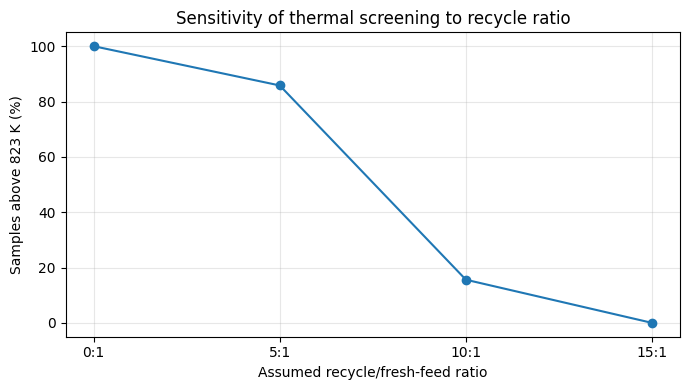

In [ ]:
# CELL 7: Recycle-ratio sensitivity
recycle_scenarios = [0.0, 5.0, 10.0, 15.0]
sensitivity_rows = []
for recycle in recycle_scenarios:
    temps = np.array([
        calculate_peak_temperature(T_inlet[i], Pressure[i], GHSV[i],
                                   H2_CO_ratio[i], yield_fraction[i], recycle)
        for i in range(num_samples)
    ])
    sensitivity_rows.append({
        "Recycle_Ratio": f"{recycle:.0f}:1",
        "Minimum_Tpeak_K": temps.min(),
        "Maximum_Tpeak_K": temps.max(),
        "Mean_Tpeak_K": temps.mean(),
        "Samples_Above_823K_pct": np.mean(temps > T_SCREEN)*100
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df.round(2))

plt.figure(figsize=(7, 4))
plt.plot(sensitivity_df["Recycle_Ratio"],
         sensitivity_df["Samples_Above_823K_pct"], marker="o")
plt.xlabel("Assumed recycle/fresh-feed ratio")
plt.ylabel("Samples above 823 K (%)")
plt.title("Sensitivity of thermal screening to recycle ratio")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("recycle_sensitivity_revised.png", dpi=250)
plt.show()


,Controller,Peak_Temperature_K,Peak_Overshoot_K,Integrated_Excursion_K_s
0,PID,768.60,18.60,568.05
1,MPC,750.03,0.03,0.80


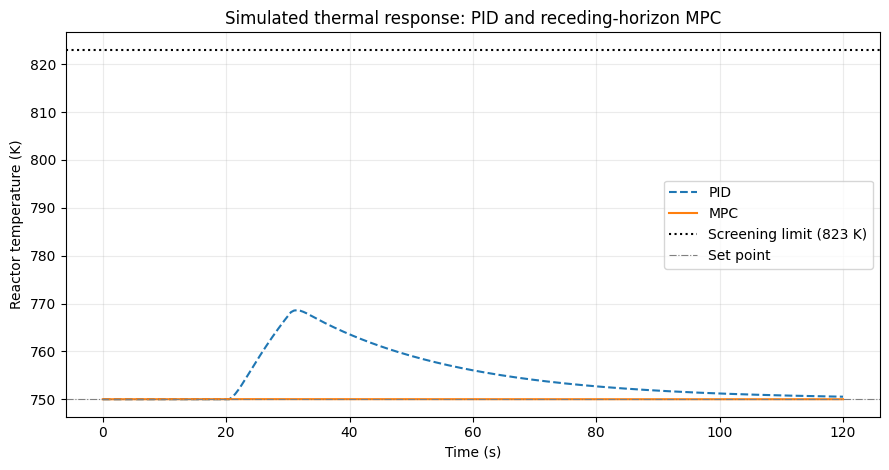

In [ ]:
# CELL 8: Receding-horizon MPC versus PID
dt = 0.5
simulation_time = 120.0
steps = int(simulation_time/dt)
T_base = 750.0
T_limit = 823.0
a_coef, b_coef, c_coef = 0.04, 3.0, 6.0
disturbance_onset = 20.0
ramp_duration = 10.0
disturbance_final = 6.0
prediction_horizon = 10

def disturbance_signal(t):
    if t < disturbance_onset:
        return 0.0
    if t < disturbance_onset+ramp_duration:
        return disturbance_final*(t-disturbance_onset)/ramp_duration
    return disturbance_final

def predict_temperature(T0, u_sequence, disturbance_value):
    temp = T0
    predicted = []
    for u in u_sequence:
        temp = temp + dt*(-a_coef*(temp-T_base)
                          + b_coef*disturbance_value-c_coef*u)
        predicted.append(temp)
    return np.asarray(predicted)

def run_pid():
    temp = T_base
    history = [temp]
    controls = []
    integral = 0.0
    previous_error = 0.0
    for k in range(steps):
        error = temp-T_base
        integral += error*dt
        derivative = (error-previous_error)/dt
        previous_error = error
        control = np.clip(0.12*error + 0.006*integral
                          + 0.01*derivative, 0.0, 3.0)
        d = disturbance_signal(k*dt)
        temp = temp + dt*(-a_coef*(temp-T_base)
                          + b_coef*d-c_coef*control)
        history.append(temp)
        controls.append(control)
    return np.asarray(history), np.asarray(controls)

def run_mpc():
    temp = T_base
    history = [temp]
    controls = []
    previous_control = 0.0
    bounds = [(0.0, 3.0)]*prediction_horizon

    for k in range(steps):
        d_est = disturbance_signal(k*dt)  # assumed upstream estimate

        def objective(u_sequence):
            predicted = predict_temperature(temp, u_sequence, d_est)
            move_penalty = 0.5*np.sum(np.diff(
                np.r_[previous_control, u_sequence])**2)
            return (np.sum((predicted-T_base)**2)
                    + 0.1*np.sum(u_sequence**2) + move_penalty)

        constraints = [{
            "type": "ineq",
            "fun": lambda u: T_limit-predict_temperature(temp, u, d_est)
        }]
        initial_guess = np.full(prediction_horizon, previous_control)
        solution = minimize(
            objective, initial_guess, method="SLSQP",
            bounds=bounds, constraints=constraints,
            options={"maxiter": 40, "ftol": 1e-5, "disp": False}
        )
        control = float(solution.x[0]) if solution.success else previous_control

        temp = temp + dt*(-a_coef*(temp-T_base)
                          + b_coef*d_est-c_coef*control)
        history.append(temp)
        controls.append(control)
        previous_control = control

    return np.asarray(history), np.asarray(controls)

pid_temperature, pid_control = run_pid()
mpc_temperature, mpc_control = run_mpc()
time_axis = np.arange(len(pid_temperature))*dt

def integrated_positive_excursion(temp):
    return float(np.trapezoid(np.maximum(temp-T_base, 0.0), dx=dt))

controller_results = pd.DataFrame([
    {
        "Controller": "PID",
        "Peak_Temperature_K": pid_temperature.max(),
        "Peak_Overshoot_K": max(0.0, pid_temperature.max()-T_base),
        "Integrated_Excursion_K_s": integrated_positive_excursion(pid_temperature)
    },
    {
        "Controller": "MPC",
        "Peak_Temperature_K": mpc_temperature.max(),
        "Peak_Overshoot_K": max(0.0, mpc_temperature.max()-T_base),
        "Integrated_Excursion_K_s": integrated_positive_excursion(mpc_temperature)
    }
])
display(controller_results.round(2))

plt.figure(figsize=(9, 4.8))
plt.plot(time_axis, pid_temperature, "--", label="PID")
plt.plot(time_axis, mpc_temperature, "-", label="MPC")
plt.axhline(T_limit, color="black", linestyle=":", label="Screening limit (823 K)")
plt.axhline(T_base, color="grey", linestyle="-.", linewidth=0.8, label="Set point")
plt.xlabel("Time (s)")
plt.ylabel("Reactor temperature (K)")
plt.title("Simulated thermal response: PID and receding-horizon MPC")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("pid_mpc_simulation_revised.png", dpi=250)
plt.show()


,Number_of_Hubs,Payload_Length_bits,Assumed_BER_percent,Estimated_Collision_Probability_percent,Estimated_PDR_percent
0,50,256,0.0001,0.4158,99.5536
1,100,256,0.0001,0.8299,99.1346
2,250,128,0.0002,2.0618,97.9131
3,500,128,0.0003,4.0811,95.8821


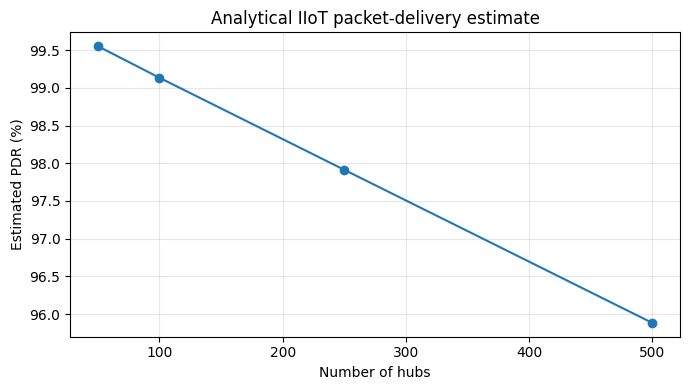

In [ ]:
# CELL 9: Analytical packet-delivery ratio
hub_counts = np.array([50, 100, 250, 500])
payload_bits = np.array([256, 256, 128, 128])
airtime_s = 0.05
reporting_interval_s = 600.0

# Explicit illustrative BER assumption; not a measured radio link.
ber = 1e-6 + hub_counts*4e-9
offered_load = hub_counts*(airtime_s/reporting_interval_s)
collision_probability = 1.0-np.exp(-offered_load)
pdr = (1.0-ber)**payload_bits * (1.0-collision_probability)

iiot_results = pd.DataFrame({
    "Number_of_Hubs": hub_counts,
    "Payload_Length_bits": payload_bits,
    "Assumed_BER_percent": ber*100.0,
    "Estimated_Collision_Probability_percent": collision_probability*100.0,
    "Estimated_PDR_percent": pdr*100.0
})
display(iiot_results.round(4))

plt.figure(figsize=(7, 4))
plt.plot(hub_counts, pdr*100.0, marker="o")
plt.xlabel("Number of hubs")
plt.ylabel("Estimated PDR (%)")
plt.title("Analytical IIoT packet-delivery estimate")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("iiot_pdr_estimate_revised.png", dpi=250)
plt.show()


In [ ]:
# CELL 10: Final summary and output files
print("="*72)
print("REVISED CPSF COMPUTATIONAL STUDY - SUMMARY")
print("="*72)
print("\nPINN and baseline model results:")
display(results.round(4))
print("\nHeat-balance sensitivity to assumed recycle ratio:")
display(sensitivity_df.round(2))
print("\nPID versus MPC simulation:")
display(controller_results.round(2))
print("\nAnalytical IIoT PDR estimate:")
display(iiot_results.round(4))

print("\nImportant interpretation:")
print("1. Dataset and methane-yield labels are synthetic.")
print("2. The heat balance is a simplified lumped adiabatic scenario.")
print("3. The 10:1 recycle ratio and 10 L bed volume are assumptions.")
print("4. MPC and IIoT outputs are simulations/analytical estimates.")
print("5. No FBG measurements, tar/CWT data, or physical LoRaWAN tests were supplied.")
print("\nCSV and figure files have been saved in the working directory.")


REVISED CPSF COMPUTATIONAL STUDY - SUMMARY

PINN and baseline model results:


,RMSE,MAE,R2,Physical_Violations_pct
Standard ANN,1.5260,0.8844,0.9240,12.5
Random Forest,0.5387,0.4035,0.9905,12.5
Proposed PINN,0.1853,0.1251,0.9989,0.0



Heat-balance sensitivity to assumed recycle ratio:


,Recycle_Ratio,Minimum_Tpeak_K,Maximum_Tpeak_K,Mean_Tpeak_K,Samples_Above_823K_pct
0,0:1,1931.72,2330.36,2170.19,100.0
1,5:1,779.28,979.64,879.24,85.8
2,10:1,663.92,859.59,761.88,15.6
3,15:1,620.32,814.57,717.87,0.0



PID versus MPC simulation:


,Controller,Peak_Temperature_K,Peak_Overshoot_K,Integrated_Excursion_K_s
0,PID,768.60,18.60,568.05
1,MPC,750.03,0.03,0.80



Analytical IIoT PDR estimate:


,Number_of_Hubs,Payload_Length_bits,Assumed_BER_percent,Estimated_Collision_Probability_percent,Estimated_PDR_percent
0,50,256,0.0001,0.4158,99.5536
1,100,256,0.0001,0.8299,99.1346
2,250,128,0.0002,2.0618,97.9131
3,500,128,0.0003,4.0811,95.8821



Important interpretation:
1. Dataset and methane-yield labels are synthetic.
2. The heat balance is a simplified lumped adiabatic scenario.
3. The 10:1 recycle ratio and 10 L bed volume are assumptions.
4. MPC and IIoT outputs are simulations/analytical estimates.
5. No FBG measurements, tar/CWT data, or physical LoRaWAN tests were supplied.

CSV and figure files have been saved in the working directory.
